# Introduction to ecological data analysis
This notebook uses the completely synthetic potato-soil dataset. It shows how a community table and metadata work together.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import spearmanr

repository_root = Path.cwd()
if not (repository_root / 'Data').exists():
    repository_root = repository_root.parent
data = repository_root / 'Data/Synthetic_Potato_Example'
counts = pd.read_csv(data / 'ITS_OTU_table_final.tsv', sep='\t', index_col=0)
metadata = pd.read_csv(data / 'Final_data_with_diversity_prefixed.csv').set_index('sample_id')
counts.head()

,SH_SYN001,SH_SYN002,SH_SYN003,SH_SYN004,SH_SYN005,SH_SYN006,SH_SYN007,SH_SYN008,SH_SYN009,SH_SYN010,...,SH_SYN191,SH_SYN192,SH_SYN193,SH_SYN194,SH_SYN195,SH_SYN196,SH_SYN197,SH_SYN198,SH_SYN199,SH_SYN200
sample_id,,,,,,,,,,,,,,,,,,,,,
Field_001.N1,11,40,69,166,3,159,105,44,7,54,...,0,1,1,3,19,66,0,0,10,6
Field_001.N2,1,3,6,23,0,15,5,3,2,5,...,0,0,0,0,0,5,0,0,1,0
Field_002.N1,27,103,34,208,37,31,453,36,9,72,...,0,0,0,14,5,23,0,0,11,4
Field_002.N2,5,38,10,55,9,10,127,5,1,26,...,0,0,1,3,1,6,0,0,2,0
Field_003.N1,1,4,8,22,4,5,18,5,7,8,...,0,0,0,0,1,2,0,0,6,0


## Reads and richness
Each row is a soil sample and each column is a fungal species hypothesis. Sequencing depth is the row sum. Richness is the number of taxa with at least one read.

In [2]:
total_reads = counts.sum(axis=1)
richness = (counts > 0).sum(axis=1)
# Exclude failed libraries, then sum raw reads and taxa to one independent field row.
nonempty = counts.loc[total_reads > 0]
field_id = nonempty.index.str.replace(r'\.N\d+$', '', regex=True)
field_counts = nonempty.assign(field_id=field_id).groupby('field_id').sum()
field_summary = pd.DataFrame({'total_reads': field_counts.sum(axis=1), 'observed_richness': (field_counts > 0).sum(axis=1)})
field_metadata = metadata.groupby('site.id').first()
summary = field_metadata.join(field_summary)
summary[['total_reads', 'observed_richness', 'pH_KCl']].head()

,total_reads,observed_richness,pH_KCl
site.id,,,
Field_001,16081,189,5.530101
Field_002,16648,190,6.098625
Field_003,2687,173,6.751106
Field_004,10409,192,6.151302
Field_005,9336,186,6.020931


## Independent fields
The two soil samples within a field are biological replicates, not two independent fields. For this field-level depth--richness correlation we exclude zero-read libraries and sum raw counts within field before calculating reads and richness.

## Why depth matters
Low-depth samples often miss rare taxa, so compare depth and observed richness before interpreting richness differences.

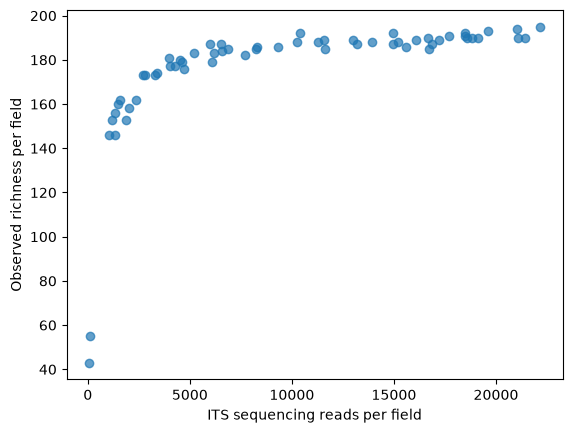

Field-level Spearman rho = 0.93, p = 2.14e-27 (n = 60 fields)


In [3]:
plt.scatter(summary.total_reads, summary.observed_richness, alpha=.7)
plt.xlabel('ITS sequencing reads per field'); plt.ylabel('Observed richness per field'); plt.show()
rho, p = spearmanr(summary.total_reads, summary.observed_richness)
print(f'Field-level Spearman rho = {rho:.2f}, p = {p:.3g} (n = {len(summary)} fields)')

## Shannon diversity
Shannon diversity combines richness and evenness. Empty libraries are excluded because proportions are undefined.

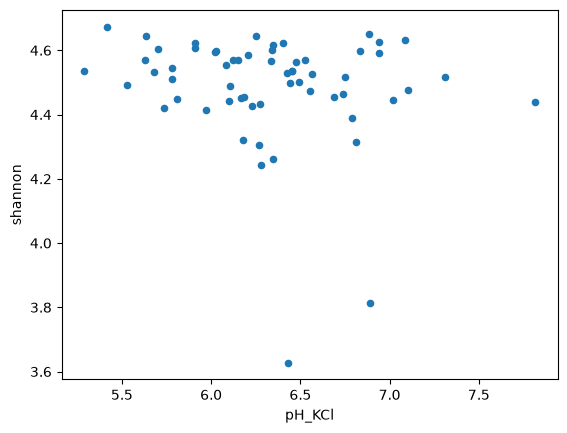

In [4]:
field_proportions = field_counts.div(field_counts.sum(axis=1), axis=0)
positive = field_proportions.where(field_proportions > 0, 1)
shannon = -(positive * np.log(positive)).sum(axis=1)
summary['shannon'] = shannon
summary[['pH_KCl', 'shannon']].plot.scatter(x='pH_KCl', y='shannon')
plt.show()

Interpret associations as teaching examples only. The synthetic README describes the deliberately simulated relationships.

Sequence reads are measurements, not direct organism counts or biomass. All relationships here are simulated teaching examples, not real ecological findings.